# Cardiovascular disease prediction

Does a short medical check-up predict cardiovascular disease?

**Data:** Cardiovascular Disease dataset (Kaggle), 70,000 patients with age, sex, height, weight, blood pressure, cholesterol, glucose and lifestyle factors. `cardio = 1` means disease.

**Cleaning:** age is converted from days to years, BMI is computed from height and weight, and rows with impossible values (for example negative blood pressure, or diastolic above systolic) are removed.

Every model below uses **the same stratified train/test split** (80/20, fixed seed). Imputation and scaling are fitted on the training data only. Models are compared with 5-fold cross-validation on the training set and scored once on the held-out test set. The shared code is in [`../src/disease_ml.py`](../src/disease_ml.py).

In [1]:
import sys
sys.path.insert(0, '../src')

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import disease_ml as dm

pd.set_option('display.precision', 3)

## 1. Data

In [2]:
X, y = dm.load_cardio()
LABELS = ['No disease', 'Disease']

print(f'{X.shape[0]:,} patients, {X.shape[1]} features')
X.head()

68,608 patients, 12 features


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,bmi
0,50.4,2,168,62.0,110,80,1,1,0,0,1,22.0
1,55.4,1,156,85.0,140,90,3,1,0,0,1,34.9
2,51.6,1,165,64.0,130,70,3,1,0,0,0,23.5
3,48.2,2,169,82.0,150,100,1,1,0,0,1,28.7
4,47.8,1,156,56.0,100,60,1,1,0,0,0,23.0


In [3]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
age,68608.0,53.292,6.757,29.6,48.3,53.9,58.4,64.9
gender,68608.0,1.349,0.477,1.0,1.0,1.0,2.0,2.0
height,68608.0,164.414,7.913,120.0,159.0,165.0,170.0,207.0
weight,68608.0,74.116,14.296,30.0,65.0,72.0,82.0,200.0
ap_hi,68608.0,126.677,16.679,80.0,120.0,120.0,140.0,240.0
ap_lo,68608.0,81.306,9.427,40.0,80.0,80.0,90.0,160.0
cholesterol,68608.0,1.365,0.679,1.0,1.0,1.0,2.0,3.0
gluc,68608.0,1.226,0.572,1.0,1.0,1.0,1.0,3.0
smoke,68608.0,0.088,0.283,0.0,0.0,0.0,0.0,1.0
alco,68608.0,0.053,0.225,0.0,0.0,0.0,0.0,1.0


## 2. Exploration

How balanced are the two classes, and which features move with the target?

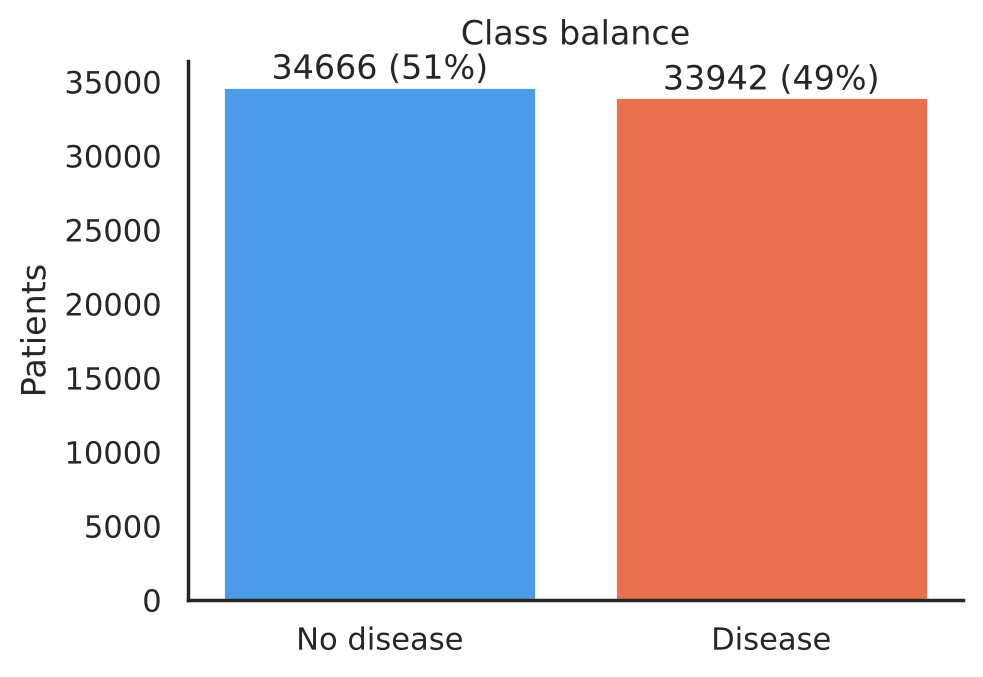

In [4]:
fig = dm.plot_class_balance(y, LABELS, 'Class balance')
dm.save(fig, 'cardio_class_balance')

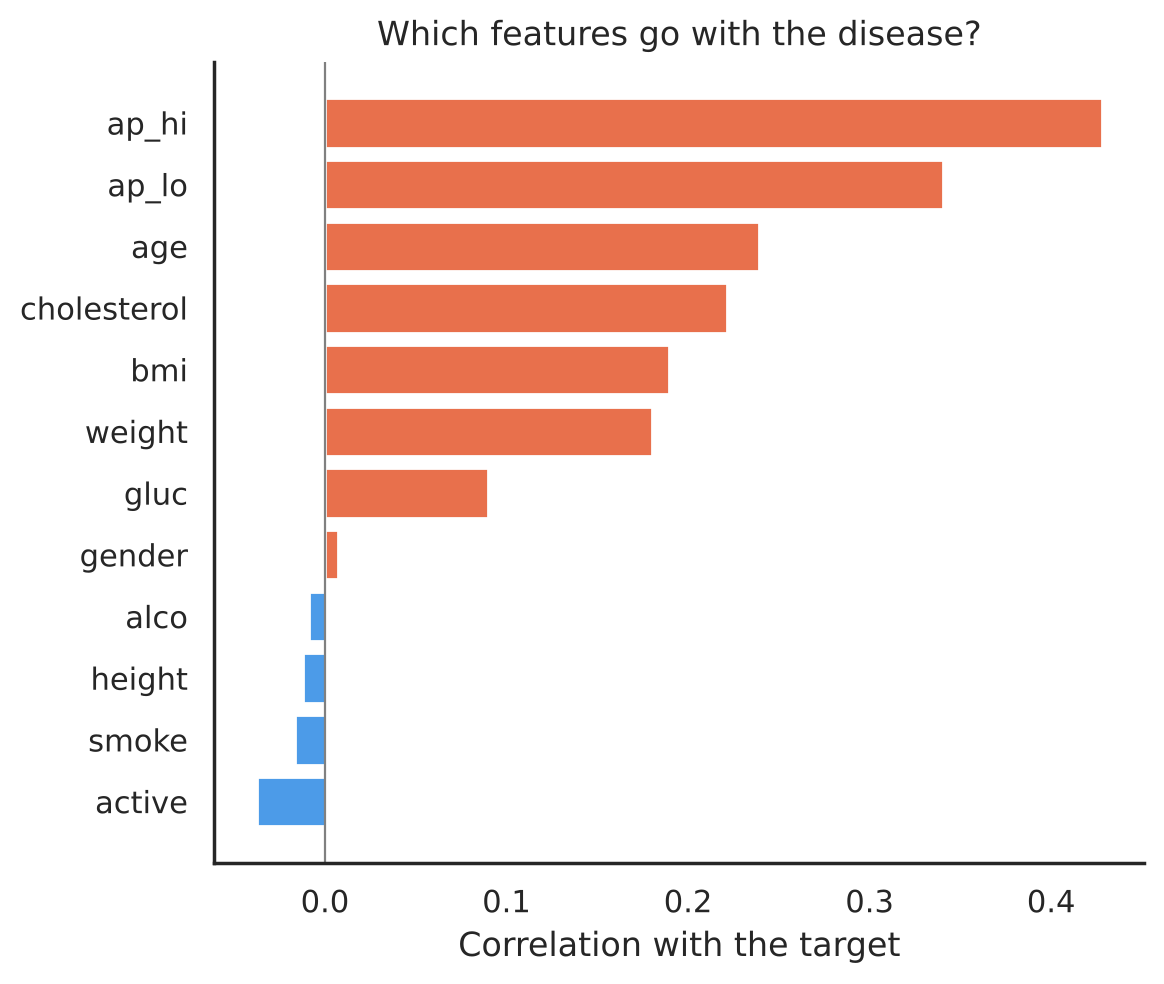

In [5]:
fig = dm.plot_correlation_with_target(X, y, 'Which features go with the disease?')
dm.save(fig, 'cardio_correlation')

## 3. Classical models

In [6]:
X_train, X_test, y_train, y_test = dm.split(X, y)
models = dm.make_models(large=True, with_smote=False)

results, fitted = dm.evaluate_models(models, X_train, X_test, y_train, y_test)
results.sort_values('test_roc_auc', ascending=False)

,cv_accuracy,cv_accuracy_std,cv_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
model,,,,,,,,
Random forest,0.730,0.002,0.792,0.728,0.744,0.688,0.715,0.796
SVM (linear),0.726,0.003,0.791,0.727,0.760,0.654,0.703,0.793
Logistic regression,0.727,0.002,0.791,0.727,0.756,0.662,0.706,0.793
Decision tree,0.729,0.001,0.791,0.735,0.762,0.674,0.715,0.792
k-nearest neighbours,0.719,0.003,0.775,0.720,0.731,0.688,0.709,0.781
Naive Bayes,0.707,0.003,0.773,0.706,0.753,0.604,0.670,0.775
Baseline (majority class),0.505,0.000,0.500,0.505,0.000,0.000,0.000,0.500


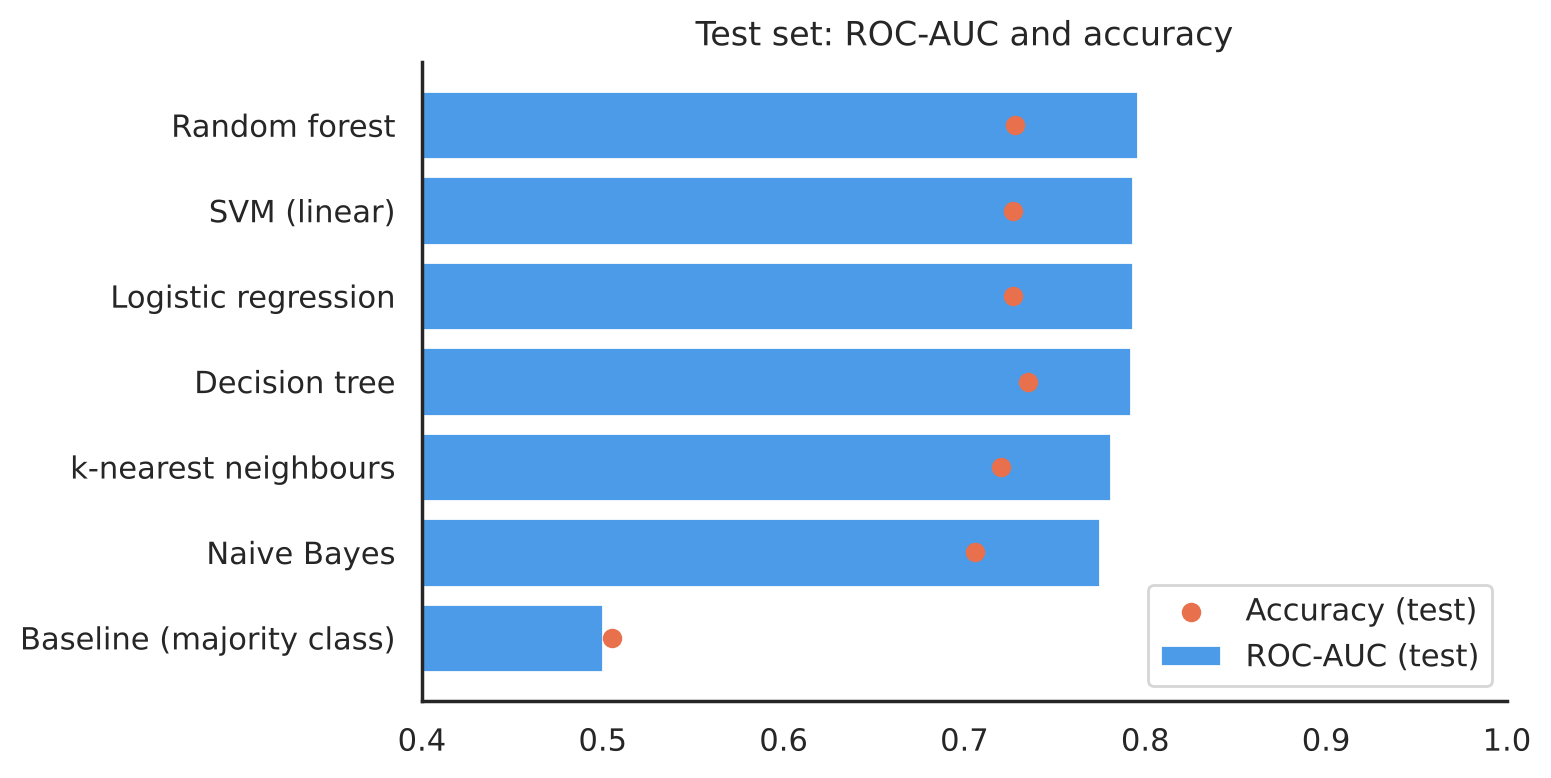

In [7]:
fig = dm.plot_model_comparison(results, 'Test set: ROC-AUC and accuracy')
dm.save(fig, 'cardio_model_comparison')

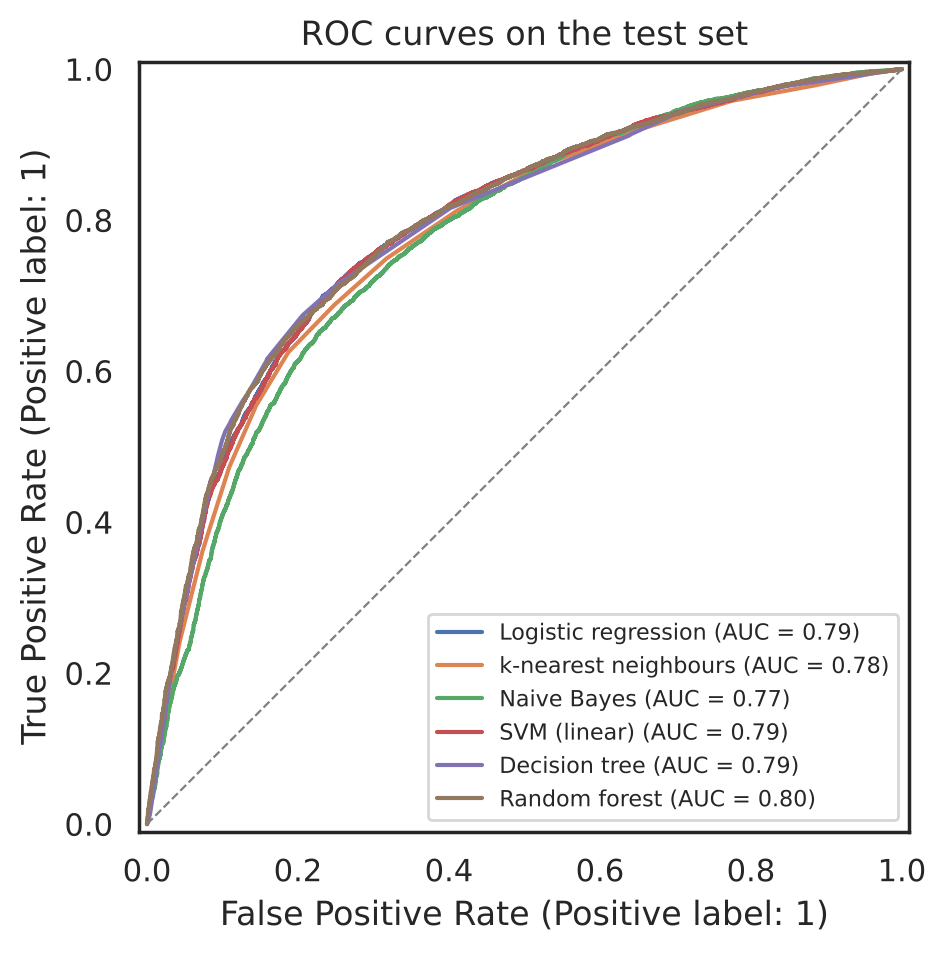

In [8]:
fig = dm.plot_roc_curves(fitted, X_test, y_test, 'ROC curves on the test set')
dm.save(fig, 'cardio_roc_curves')

Best model by test ROC-AUC: Random forest


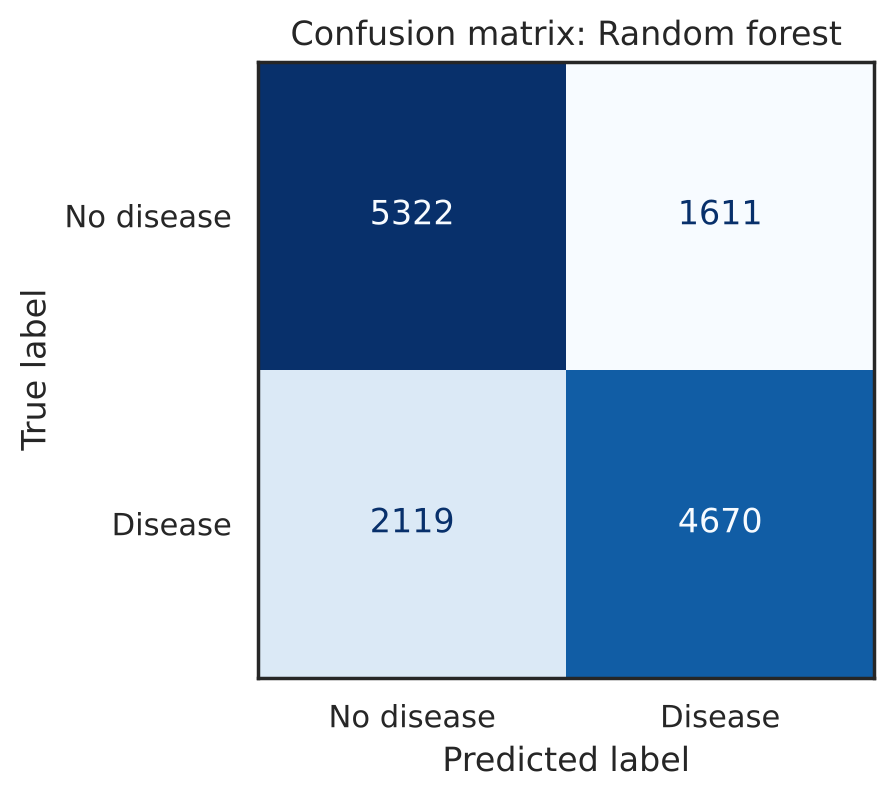

In [9]:
best = results.drop(index='Baseline (majority class)')['test_roc_auc'].idxmax()
fig = dm.plot_confusion(fitted[best], X_test, y_test, LABELS, f'Confusion matrix: {best}')
dm.save(fig, 'cardio_confusion_best')
print('Best model by test ROC-AUC:', best)

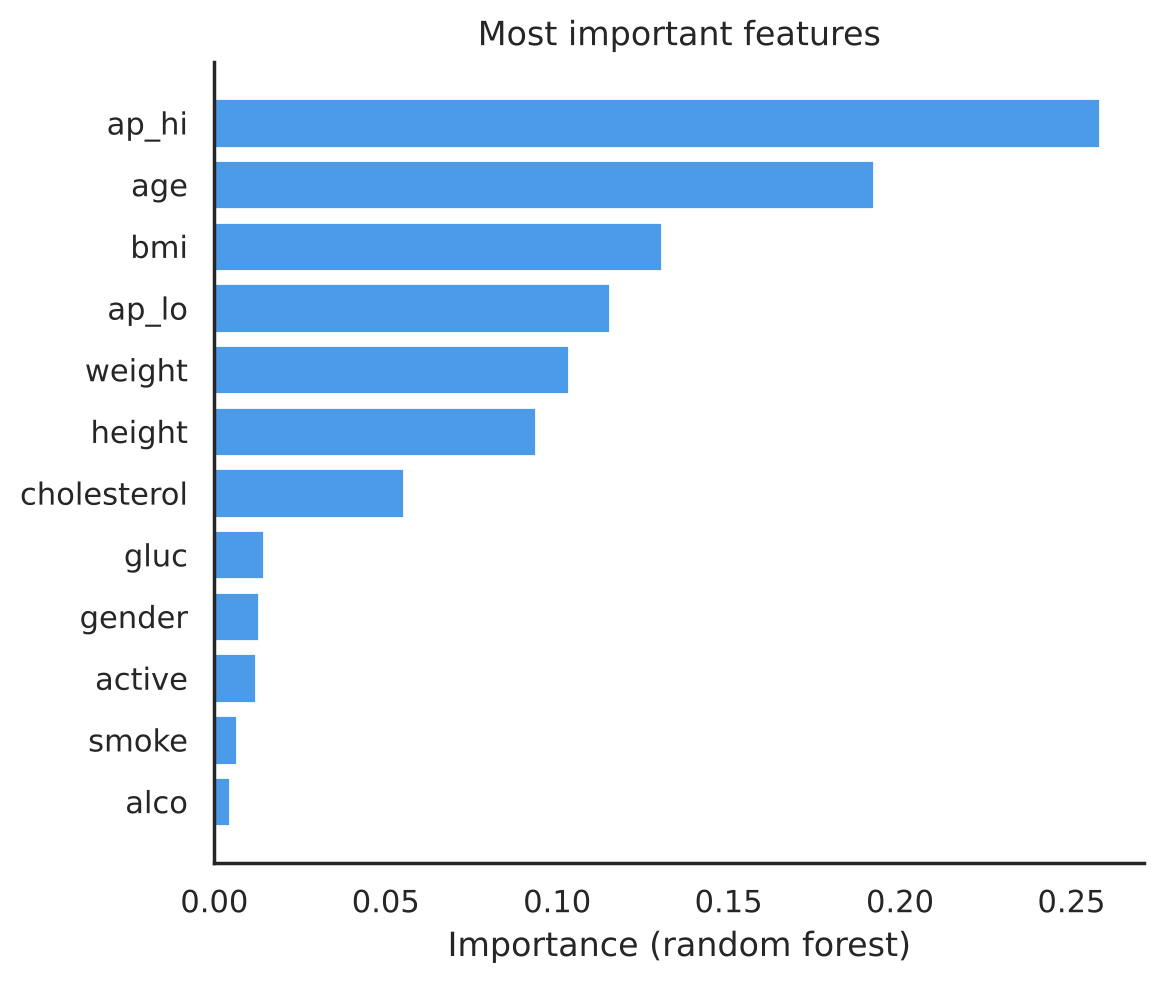

In [10]:
fig = dm.plot_feature_importance(fitted['Random forest'], X.columns, 'Most important features')
dm.save(fig, 'cardio_feature_importance')

## 4. Neural network

A small Keras network (16 → 8 → 1 neurons, dropout, early stopping) trained on the same split.

I0000 00:00:1795493537.488317   11876 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795493538.697544   11876 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


test_accuracy      0.732
test_precision     0.764
test_recall        0.663
test_f1            0.710
test_roc_auc       0.802
epochs_trained    66.000
dtype: float64

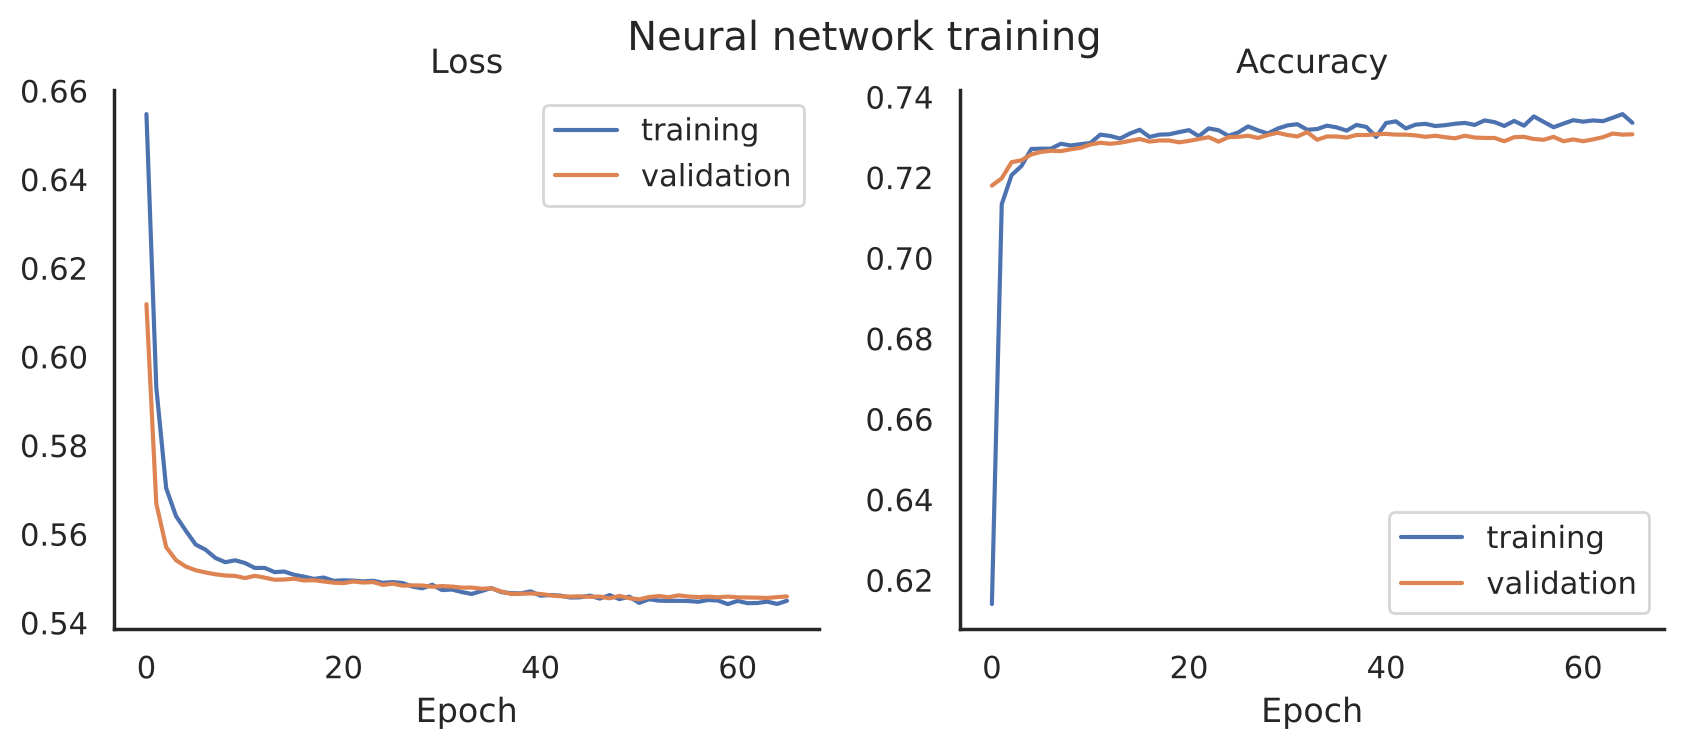

In [11]:
ann, history, ann_metrics = dm.train_ann(X_train, X_test, y_train, y_test)
fig = dm.plot_history(history, 'Neural network training')
dm.save(fig, 'cardio_ann_training')
pd.Series(ann_metrics)

## 5. Summary table

In [12]:
summary = results[['cv_accuracy', 'cv_roc_auc', 'test_accuracy', 'test_recall', 'test_f1', 'test_roc_auc']].copy()
summary.loc['Neural network (Keras)'] = [None, None, ann_metrics['test_accuracy'], ann_metrics['test_recall'],
                                         ann_metrics['test_f1'], ann_metrics['test_roc_auc']]
summary = summary.sort_values('test_roc_auc', ascending=False)
dm.RESULTS_DIR.mkdir(exist_ok=True)
summary.to_csv(dm.RESULTS_DIR / 'cardio_results.csv')
summary

,cv_accuracy,cv_roc_auc,test_accuracy,test_recall,test_f1,test_roc_auc
model,,,,,,
Neural network (Keras),NaN,NaN,0.732,0.663,0.710,0.802
Random forest,0.730,0.792,0.728,0.688,0.715,0.796
Logistic regression,0.727,0.791,0.727,0.662,0.706,0.793
SVM (linear),0.726,0.791,0.727,0.654,0.703,0.793
Decision tree,0.729,0.791,0.735,0.674,0.715,0.792
k-nearest neighbours,0.719,0.775,0.720,0.688,0.709,0.781
Naive Bayes,0.707,0.773,0.706,0.604,0.670,0.775
Baseline (majority class),0.505,0.500,0.505,0.000,0.000,0.500


## 6. Conclusion

- **All models end up close together:** test ROC-AUC between **0.78 and 0.80** and accuracy around **73 %**, against 50 % for guessing. The neural network is marginally best (ROC-AUC 0.80), logistic regression is practically as good.
- **What this means:** the limit here is the information in the data, not the choice of model. Blood pressure, age, BMI and cholesterol carry most of the signal; a short check-up cannot separate the two groups much better than this.
- **Most important features:** systolic blood pressure (`ap_hi`), age, BMI and diastolic blood pressure (`ap_lo`).
- **Cleaning matters:** 1,392 rows (2 %) with impossible values, such as negative or five-digit blood pressure, were removed before training.
- With 13,722 patients in the test set, these numbers are stable; differences of 0.01 are still too small to call one model better.